# Cross-Resolution Multi-Scale Ensemble Pipeline (v5)
### Blending High-Capacity Macro ($K = 100$) and High-Resolution Intraday ($K = 50$) Models
**Metric:** Global Pearson Correlation Coefficient (PCC) across the continuous 24,431-step forecast  
**Horizon:** 24,431 consecutive 1-minute Close prices (~17 days, IDs 500,000 to 524,430) from 500,000 historical intervals

---

### Core Architectural Design in v5:
This pipeline implements a **Cross-Resolution Multi-Scale Ensemble** that combines two specialized neural architectures operating at different temporal scales:

| Component | Model 1: Macro-Scale ($K = 100$) | Model 2: Sub-Macro Scale ($K = 50$) |
| :--- | :--- | :--- |
| **Downsample Factor** | $K_1 = 100$ minutes | $K_2 = 50$ minutes |
| **Output Horizon** | $K_{\text{target}} = 245$ macro knots | $K_{\text{target}} = 489$ macro knots (2× higher density) |
| **Lookback Window** | 200 bars (~13.9 days) | 400 bars (~13.9 days) |
| **Momentum Spans** | Fast: 30 bars (~2.1d) \| Slow: 150 bars (~10.4d) | Fast: 60 bars (~2.1d) \| Slow: 300 bars (~10.4d) |
| **Volume & RSI** | Vol: 20 bars (~1.4d) \| RSI: 14 bars (~1d) | Vol: 40 bars (~1.4d) \| RSI: 28 bars (~1d) |
| **Sample Stride** | `stride = 3` (5.0 hours) | `stride = 6` (5.0 hours) |
| **Architecture** | `Conv1D(64)` + `BiGRU(64)` + `Dense(96)` | `Conv1D(64)` + `BiGRU(64)` + `Dense(128)` |
| **Specialization** | Ultra-smooth macro cycle orientation | Responsive intraday inflection & turning point detection |

### Log-Trajectory Blending & Continuous PCHIP Splines:
1. Each model predicts its native macro log-trajectory ($z^{(1)}$ of length 245, $z^{(2)}$ of length 489).
2. Monotonic PCHIP cubic splines expand each trajectory into continuous 24,431-minute vectors: $\hat{z}_1(t)$ and $\hat{z}_2(t)$.
3. The ensemble blends the trajectories via simple averaging in log-space:
   $$\hat{z}_{\text{ens}}(t) = 0.5 \cdot \hat{z}_1(t) + 0.5 \cdot \hat{z}_2(t)$$
4. Enforcing exact continuity at $t=0$: $\hat{z}_{\text{ens}}(t) = \hat{z}_{\text{ens}}(t) - \hat{z}_{\text{ens}}(0)$.
5. Reconstructing prices via exponential mapping: $\hat{P}_t = P_{\text{last}} \cdot \exp(\hat{z}_{\text{ens}}(t))$, which acts as an optimal **geometric mean** of the two predictions.


In [79]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy import stats

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Strict Global Seeding for Complete Determinism & Reproducibility
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)
# Enforce deterministic ops in TensorFlow (critical for GPU reproducibility)
tf.config.experimental.enable_op_determinism()

print(f"TensorFlow Version: {tf.__version__}")
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print(f"Global Random Seed set to: {SEED}")


TensorFlow Version: 2.21.0
Num GPUs Available:  1
Global Random Seed set to: 42


## 1. Data Ingestion & Dual Model Configurations
We load the historical dataset and configure distinct parameter sets for Model 1 ($K = 100$) and Model 2 ($K = 50$).


In [80]:
DATA_PATH = 'tXY.csv'
SAMPLE_SUB_PATH = 'sampleSubmission.csv'

tXY = pd.read_csv(DATA_PATH, index_col='id')
pY = pd.read_csv(SAMPLE_SUB_PATH, index_col='id')

N_TOTAL = len(tXY)
N_FORECAST = len(pY)  # Exactly 24,431 steps
#-----------------------------------------------------------------
# Model 1 Parameters (K = 100, Macro-Scale)
K1 = 100
TARGET_STEPS_1 = math.ceil(N_FORECAST / K1)  # 245 steps
LOOKBACK_1 = 200
FAST_SPAN_1 = 30
SLOW_SPAN_1 = 150
VOL_SPAN_1 = 20
RSI_PERIOD_1 = 14
STRIDE_1 = 3
#-----------------------------------------------------------------
# Model 2 Parameters (K = 50, Sub-Macro Scale)
K2 = 50
TARGET_STEPS_2 = math.ceil(N_FORECAST / K2)  # 489 steps
LOOKBACK_2 = 400
FAST_SPAN_2 = 60
SLOW_SPAN_2 = 300
VOL_SPAN_2 = 40
RSI_PERIOD_2 = 28
STRIDE_2 = 6

print(f"Total dataset observations: {N_TOTAL:,}")
print(f"Model 1 (K=100): Horizon={TARGET_STEPS_1} steps, Lookback={LOOKBACK_1} bars, Spans=({FAST_SPAN_1}/{SLOW_SPAN_1}), Stride={STRIDE_1}")
print(f"Model 2 (K=50):  Horizon={TARGET_STEPS_2} steps, Lookback={LOOKBACK_2} bars, Spans=({FAST_SPAN_2}/{SLOW_SPAN_2}), Stride={STRIDE_2}")
display(tXY.head(3))


Total dataset observations: 500,000
Model 1 (K=100): Horizon=245 steps, Lookback=200 bars, Spans=(30/150), Stride=3
Model 2 (K=50):  Horizon=489 steps, Lookback=400 bars, Spans=(60/300), Stride=6


,Count,Open,High,Low,Close,Volume,VWAP
id,,,,,,,
0,64,0.2017,0.2022,0.2015,0.2017,447,0.2020
1,72,0.2025,0.2028,0.2023,0.2024,592,0.2024
2,63,0.2019,0.2021,0.2017,0.2021,470,0.2020


## 2. Multi-Resolution Resampling & Stationary Feature Engineering
We construct dedicated feature engineering pipelines tailored to each model's time-scale.


In [81]:
def resample_ohlcv(df: pd.DataFrame, factor: int) -> pd.DataFrame:
    """
    Downsamples a 1-minute dataframe into macro bars using financial OHLCV aggregation rules.
    """
    groups = np.arange(len(df)) // factor
    vwap_num = (df['VWAP'] * df['Volume']).groupby(groups).sum()
    vol_sum = df['Volume'].groupby(groups).sum()
    macro_vwap = np.where(vol_sum > 0, vwap_num / vol_sum, df['Close'].groupby(groups).last())

    macro_df = pd.DataFrame({
        'Open': df['Open'].groupby(groups).first(),
        'High': df['High'].groupby(groups).max(),
        'Low': df['Low'].groupby(groups).min(),
        'Close': df['Close'].groupby(groups).last(),
        'Volume': vol_sum,
        'Count': df['Count'].groupby(groups).sum(),
        'VWAP': macro_vwap
    })
    macro_df.index.name = 'macro_id'
    return macro_df

def compute_rsi(series: pd.Series, period: int) -> pd.Series:
    """
    Computes Relative Strength Index (RSI) normalized to [-1, 1] centered at 50.
    """
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(com=period - 1, min_periods=period).mean()
    avg_loss = loss.ewm(com=period - 1, min_periods=period).mean()
    rs = avg_gain / (avg_loss + 1e-8)
    rsi = 100.0 - (100.0 / (1.0 + rs))
    return (rsi - 50.0) / 50.0

def engineer_features_k100(df: pd.DataFrame) -> pd.DataFrame:
    """
    Constructs 12 scale-invariant stationary features for K = 100.
    """
    feat = pd.DataFrame(index=df.index)
    feat['Close'] = df['Close']

    ema_fast = df['Close'].ewm(span=FAST_SPAN_1, adjust=False).mean()
    ema_slow = df['Close'].ewm(span=SLOW_SPAN_1, adjust=False).mean()
    feat['spread_fast_slow'] = (ema_fast - ema_slow) / (ema_slow + 1e-8)
    feat['dist_from_fast'] = (df['Close'] - ema_fast) / (ema_fast + 1e-8)
    feat['dist_from_slow'] = (df['Close'] - ema_slow) / (ema_slow + 1e-8)

    feat['hl_range'] = (df['High'] - df['Low']) / (df['Close'] + 1e-8)
    feat['candle_body'] = (df['Close'] - df['Open']) / (df['High'] - df['Low'] + 1e-8)

    feat['log_return_1'] = np.log(df['Close'] / df['Close'].shift(1).replace(0, np.nan))
    feat['log_return_5'] = np.log(df['Close'] / df['Close'].shift(5).replace(0, np.nan))
    feat['rsi_norm'] = compute_rsi(df['Close'], period=RSI_PERIOD_1)

    vol_ema = df['Volume'].ewm(span=VOL_SPAN_1, adjust=False).mean()
    feat['rvol'] = np.log((df['Volume'] + 1) / (vol_ema + 1))
    count_ema = df['Count'].ewm(span=VOL_SPAN_1, adjust=False).mean()
    feat['rcount'] = np.log((df['Count'] + 1) / (count_ema + 1))

    feat['vol_momentum'] = feat['rvol'] * np.sign(feat['log_return_1'])
    feat['vwap_close_ratio'] = (df['VWAP'] - df['Close']) / (df['Close'] + 1e-8)
    return feat.bfill().ffill()

def engineer_features_k50(df: pd.DataFrame) -> pd.DataFrame:
    """
    Constructs 12 scale-invariant stationary features for K = 50.
    """
    feat = pd.DataFrame(index=df.index)
    feat['Close'] = df['Close']

    ema_fast = df['Close'].ewm(span=FAST_SPAN_2, adjust=False).mean()
    ema_slow = df['Close'].ewm(span=SLOW_SPAN_2, adjust=False).mean()
    feat['spread_fast_slow'] = (ema_fast - ema_slow) / (ema_slow + 1e-8)
    feat['dist_from_fast'] = (df['Close'] - ema_fast) / (ema_fast + 1e-8)
    feat['dist_from_slow'] = (df['Close'] - ema_slow) / (ema_slow + 1e-8)

    feat['hl_range'] = (df['High'] - df['Low']) / (df['Close'] + 1e-8)
    feat['candle_body'] = (df['Close'] - df['Open']) / (df['High'] - df['Low'] + 1e-8)

    feat['log_return_1'] = np.log(df['Close'] / df['Close'].shift(1).replace(0, np.nan))
    feat['log_return_10'] = np.log(df['Close'] / df['Close'].shift(10).replace(0, np.nan))
    feat['rsi_norm'] = compute_rsi(df['Close'], period=RSI_PERIOD_2)

    vol_ema = df['Volume'].ewm(span=VOL_SPAN_2, adjust=False).mean()
    feat['rvol'] = np.log((df['Volume'] + 1) / (vol_ema + 1))
    count_ema = df['Count'].ewm(span=VOL_SPAN_2, adjust=False).mean()
    feat['rcount'] = np.log((df['Count'] + 1) / (count_ema + 1))

    feat['vol_momentum'] = feat['rvol'] * np.sign(feat['log_return_1'])
    feat['vwap_close_ratio'] = (df['VWAP'] - df['Close']) / (df['Close'] + 1e-8)
    return feat.bfill().ffill()

FEATURE_COLS_K100 = ['spread_fast_slow', 'dist_from_fast', 'dist_from_slow', 'hl_range', 'candle_body',
                     'log_return_1', 'log_return_5', 'rsi_norm', 'rvol', 'rcount', 'vol_momentum', 'vwap_close_ratio']

FEATURE_COLS_K50 = ['spread_fast_slow', 'dist_from_fast', 'dist_from_slow', 'hl_range', 'candle_body',
                    'log_return_1', 'log_return_10', 'rsi_norm', 'rvol', 'rcount', 'vol_momentum', 'vwap_close_ratio']


## 3. Calibrated Joint Objective & Evaluation Metrics
We optimize the sequence-level Pearson correlation augmented with an MSE scale anchor:
$$\mathcal{L}(y_{\text{true}}, y_{\text{pred}}) = -\text{PCC}(y_{\text{true}}, y_{\text{pred}}) + 1.5 \cdot \text{MSE}(y_{\text{true}}, y_{\text{pred}})$$


In [82]:
def pearson_corr_tf(y_true, y_pred):
    """
    Computes Pearson Correlation Coefficient along the sequence horizon axis (axis=-1).
    """
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)

    x = y_true - tf.reduce_mean(y_true, axis=-1, keepdims=True)
    y = y_pred - tf.reduce_mean(y_pred, axis=-1, keepdims=True)

    covariance = tf.reduce_sum(x * y, axis=-1)
    variance_x = tf.reduce_sum(tf.square(x), axis=-1)
    variance_y = tf.reduce_sum(tf.square(y), axis=-1)

    denominator = tf.sqrt(variance_x * variance_y + 1e-8)
    corr = tf.math.divide_no_nan(covariance, denominator)
    return tf.reduce_mean(corr)

def combined_loss_tf(y_true, y_pred, lambda_mse=1.5):
    """
    Calibrated Combined Loss: -PCC + 1.5 * MSE
    """
    pcc = pearson_corr_tf(y_true, y_pred)
    mse = tf.reduce_mean(tf.square(y_true - y_pred))
    return -pcc + lambda_mse * mse

def numpy_pcc(y_true, y_pred):
    """
    NumPy Pearson Correlation matching Kaggle competition evaluation.
    """
    yt = np.asarray(y_true, dtype=np.float64).ravel()
    yp = np.asarray(y_pred, dtype=np.float64).ravel()
    return float(np.corrcoef(yt, yp)[0, 1])


## 4. Dedicated Model Builders & Dataset Generators
We provide two separate builder functions so each model can be independently customized:
1. `build_model_k100`: Optimized for $K = 100$ macro modeling (`Conv1D(64)` + `BiGRU(64)` + `Dense(96)` $\to$ 245 outputs).
2. `build_model_k50`: Optimized for $K = 50$ intraday modeling (`Conv1D(64)` + `BiGRU(64)` + `Dense(128)` $\to$ 489 outputs).


In [83]:
def create_dataset(df_feat: pd.DataFrame, feature_cols, lookback, horizon, stride):
    """
    Constructs normalized sliding windows for training.
    """
    close_series = df_feat['Close'].values
    features_data = df_feat[feature_cols].values
    X_list, y_list = [], []
    total_len = len(df_feat)

    for i in range(0, total_len - lookback - horizon + 1, stride):
        last_close = close_series[i + lookback - 1]
        x_feat = features_data[i : i + lookback]
        norm_log_price = np.log(close_series[i : i + lookback] / (last_close + 1e-8))
        X_list.append(np.column_stack([x_feat, norm_log_price]))
        y_list.append(np.log(close_series[i + lookback : i + lookback + horizon] / (last_close + 1e-8)))

    return np.array(X_list, dtype=np.float32), np.array(y_list, dtype=np.float32)

def build_model_k100(layer_size,input_shape, output_horizon=TARGET_STEPS_1, seed=SEED):
    """
    Model 1 Builder: Tailored for K = 100 with Dense(96) projection bottleneck.
    Replicates the top ~0.60 CV performance from v4b.
    """
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    keras.utils.set_random_seed(SEED)
    Init = keras.initializers.GlorotUniform(seed=seed)
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(filters=layer_size[0], kernel_size=3, padding='same', activation='relu', kernel_initializer=Init)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)

    x = layers.Bidirectional(layers.GRU(layer_size[1], return_sequences=False, kernel_initializer=Init, recurrent_initializer=Init))(x)
    x = layers.Dropout(0.3, seed=seed)(x)

    x = layers.Dense(layer_size[2], activation='relu', kernel_initializer=Init)(x)
    x = layers.Dropout(0.2, seed=seed)(x)
    outputs = layers.Dense(output_horizon, activation='linear', kernel_initializer=Init)(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="Model_K100")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=combined_loss_tf, metrics=[pearson_corr_tf, 'mse'])
    return model

def build_model_k50(layer_size,input_shape, output_horizon=TARGET_STEPS_2, seed=SEED):
    """
    Model 2 Builder: Tailored for K = 50 high-resolution modeling with Dense(128).
    Replicates the top v4c performance.
    """
    tf.random.set_seed(SEED)
    keras.utils.set_random_seed(SEED)
    Init = keras.initializers.GlorotUniform(seed=seed)
    inputs = layers.Input(shape=input_shape)
    x = layers.Conv1D(filters=layer_size[0], kernel_size=3, padding='same', activation='relu', kernel_initializer=Init)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(pool_size=2)(x)

    x = layers.Bidirectional(layers.GRU(layer_size[1], return_sequences=False, kernel_initializer=Init, recurrent_initializer=Init))(x)
    x = layers.Dropout(0.3, seed=seed)(x)

    x = layers.Dense(layer_size[2], activation='relu', kernel_initializer=Init)(x)
    x = layers.Dropout(0.2, seed=seed)(x)
    outputs = layers.Dense(output_horizon, activation='linear', kernel_initializer=Init)(x)

    model = keras.Model(inputs=inputs, outputs=outputs, name="Model_K50")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss=combined_loss_tf, metrics=[pearson_corr_tf, 'mse'])
    return model


## 5. 3-Fold Purged Walk-Forward Cross-Validation
We evaluate out-of-sample performance across 3 distinct sequential 24,431-step historical regimes (~51 days total):
- **Fold 1 (Consolidation $\to$ Breakout):** Rows 426,707 to 451,137
- **Fold 2 (Continuation Breakout):** Rows 451,138 to 475,568
- **Fold 3 (Mountain Rally & Retracement):** Rows 475,569 to 499,999

In each fold:
1. Model 1 ($K=100$) and Model 2 ($K=50$) are trained from scratch with strict causal feature isolation.
2. Predictions are expanded to 24,431 continuous steps via PCHIP cubic splines.
3. The ensemble blends the two log-trajectories: $\hat{z}_{\text{ens}} = 0.5 \hat{z}_1 + 0.5 \hat{z}_2$.
4. We evaluate individual model correlations alongside the ensemble correlation to measure diversification gain.



Running Walk-Forward Fold 1/3: Consolidation / Early Bull
Train split: rows 0 to 426,706 | Validation block: rows 426,707 to 451,137 (24,431 steps)
Fold 1 Model 1 (K=100) samples: 1,275
Fold 1 Model 2 (K=50)  samples: 1,275
Fold 1 Scores: Model 1 (K=100) = 0.0459 | Model 2 (K=50) = 0.8463 | ENSEMBLE = 0.8948
Fold 1 Ranges: True [0.1956, 0.9024] | Ens [0.2160, 0.2344]

Running Walk-Forward Fold 2/3: Strong Breakout
Train split: rows 0 to 451,137 | Validation block: rows 451,138 to 475,568 (24,431 steps)
Fold 2 Model 1 (K=100) samples: 1,356
Fold 2 Model 2 (K=50)  samples: 1,356
Fold 2 Scores: Model 1 (K=100) = 0.6551 | Model 2 (K=50) = 0.2705 | ENSEMBLE = 0.3923
Fold 2 Ranges: True [0.7596, 1.3688] | Ens [0.8147, 0.9639]

Running Walk-Forward Fold 3/3: Mountain Rally & Crash
Train split: rows 0 to 475,568 | Validation block: rows 475,569 to 499,999 (24,431 steps)
Fold 3 Model 1 (K=100) samples: 1,438
Fold 3 Model 2 (K=50)  samples: 1,438
Fold 3 Scores: Model 1 (K=100) = 0.8168 | Model 

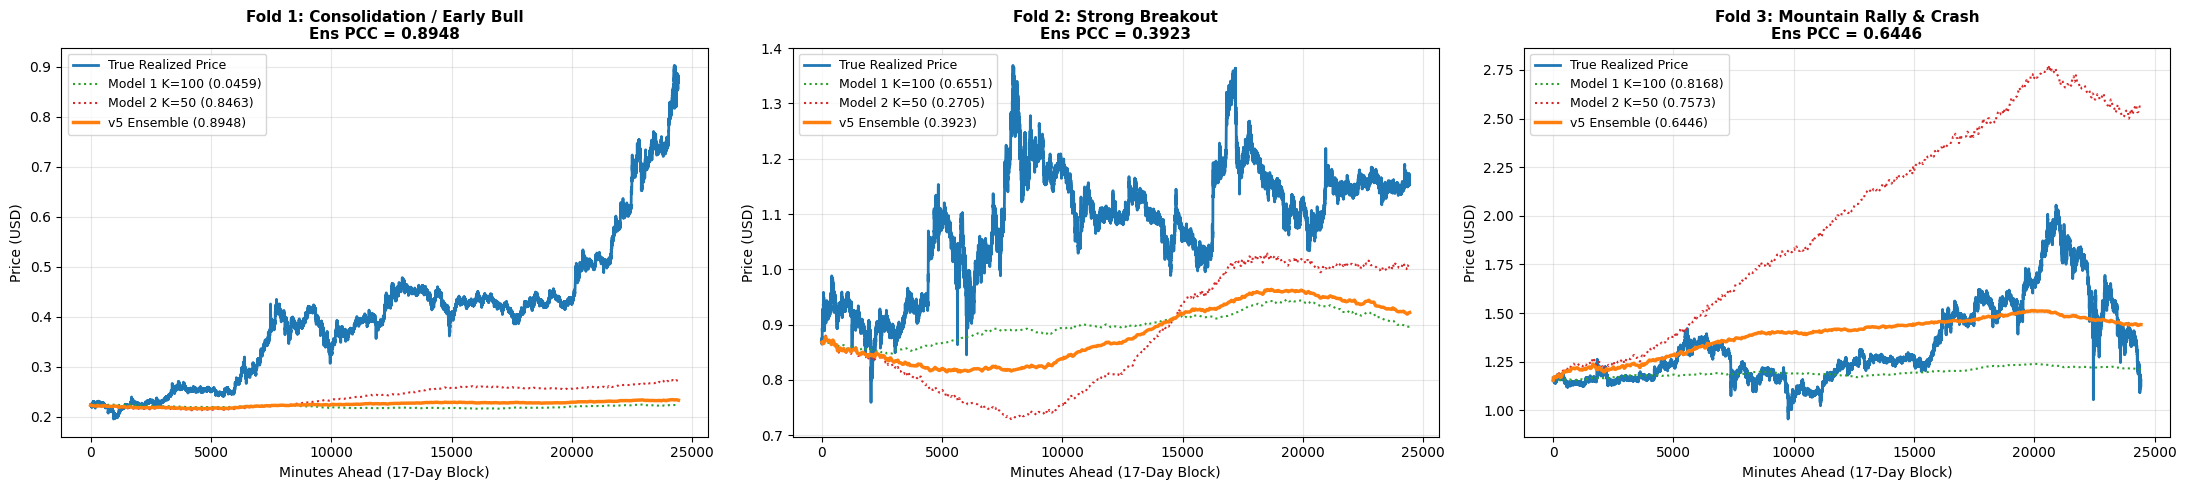


*** 3-FOLD CROSS-RESOLUTION ENSEMBLE CV SUMMARY (v5) ***
 fold                       name  pcc_m1_k100  pcc_m2_k50  pcc_ensemble
    1 Consolidation / Early Bull     0.045890    0.846310      0.894792
    2            Strong Breakout     0.655128    0.270528      0.392271
    3     Mountain Rally & Crash     0.816832    0.757287      0.644605
--------------------------------------------------------------------------------
Model 1 (K=100) Mean CV: 0.5060 +/- 0.4065 ([0.0459 0.6551 0.8168])
Model 2 (K=50)  Mean CV: 0.6247 +/- 0.3099 ([0.8463 0.2705 0.7573])
v5 ENSEMBLE     Mean CV: 0.6439 +/- 0.2513 ([0.8948 0.3923 0.6446])


In [84]:
folds_config = [
    {'fold': 1, 'val_start': N_TOTAL - 3 * N_FORECAST, 'val_end': N_TOTAL - 2 * N_FORECAST, 'name': 'Consolidation / Early Bull'},
    {'fold': 2, 'val_start': N_TOTAL - 2 * N_FORECAST, 'val_end': N_TOTAL - 1 * N_FORECAST, 'name': 'Strong Breakout'},
    {'fold': 3, 'val_start': N_TOTAL - 1 * N_FORECAST, 'val_end': N_TOTAL,                  'name': 'Mountain Rally & Crash'}
]

macro_x1 = np.linspace(0, N_FORECAST - 1, TARGET_STEPS_1)
macro_x2 = np.linspace(0, N_FORECAST - 1, TARGET_STEPS_2)
full_x = np.arange(N_FORECAST)

cv_results = []
fig, axes = plt.subplots(1, 3, figsize=(22, 5))

for fold_info in folds_config:
    fn = fold_info['fold']
    vs, ve = fold_info['val_start'], fold_info['val_end']
    name = fold_info['name']

    print(f"\n{'='*75}")
    print(f"Running Walk-Forward Fold {fn}/3: {name}")
    print(f"Train split: rows 0 to {vs-1:,} | Validation block: rows {vs:,} to {ve-1:,} ({ve-vs:,} steps)")
    print(f"{'='*75}")

    df_train = tXY.iloc[:vs].copy()
    df_val = tXY.iloc[vs:ve].copy()
    true_p = df_val['Close'].values
    last_c = float(df_train['Close'].iloc[-1])

    # --- 1. Model 1 (K = 100) ---
    m1_layer_size = [32,32,128]

    m1_tr = resample_ohlcv(df_train, factor=K1)
    m1_feat = engineer_features_k100(m1_tr)
    X1, y1 = create_dataset(m1_feat, FEATURE_COLS_K100, LOOKBACK_1, TARGET_STEPS_1, STRIDE_1)
    print(f"Fold {fn} Model 1 (K=100) samples: {len(X1):,}")

    model_m1 = build_model_k100(layer_size=m1_layer_size,input_shape=(X1.shape[1], X1.shape[2]), output_horizon=TARGET_STEPS_1, seed=SEED + fn)
    model_m1.fit(X1, y1, epochs=25, batch_size=32, verbose=0)

    last_w1 = m1_feat.iloc[-LOOKBACK_1:]
    norm_lp1 = np.log(last_w1['Close'].values / (last_c + 1e-8))
    inp1 = np.column_stack([last_w1[FEATURE_COLS_K100].values, norm_lp1])[np.newaxis, ...]
    pred_log1 = model_m1.predict(inp1, verbose=0)[0]
    pred_log1 = pred_log1 - pred_log1[0]
    pchip1 = PchipInterpolator(macro_x1, pred_log1)
    dense_log1 = pchip1(full_x)
    pred_p1 = last_c * np.exp(dense_log1)
    pcc1 = numpy_pcc(true_p, pred_p1)

    # --- 2. Model 2 (K = 50) ---
    m2_layer_size = [32,64,64]

    m2_tr = resample_ohlcv(df_train, factor=K2)
    m2_feat = engineer_features_k50(m2_tr)
    X2, y2 = create_dataset(m2_feat, FEATURE_COLS_K50, LOOKBACK_2, TARGET_STEPS_2, STRIDE_2)
    print(f"Fold {fn} Model 2 (K=50)  samples: {len(X2):,}")

    model_m2 = build_model_k50(layer_size=m2_layer_size,input_shape=(X2.shape[1], X2.shape[2]), output_horizon=TARGET_STEPS_2, seed=SEED + fn)
    model_m2.fit(X2, y2, epochs=25, batch_size=32, verbose=0)

    last_w2 = m2_feat.iloc[-LOOKBACK_2:]
    norm_lp2 = np.log(last_w2['Close'].values / (last_c + 1e-8))
    inp2 = np.column_stack([last_w2[FEATURE_COLS_K50].values, norm_lp2])[np.newaxis, ...]
    pred_log2 = model_m2.predict(inp2, verbose=0)[0]
    pred_log2 = pred_log2 - pred_log2[0]
    pchip2 = PchipInterpolator(macro_x2, pred_log2)
    dense_log2 = pchip2(full_x)
    pred_p2 = last_c * np.exp(dense_log2)
    pcc2 = numpy_pcc(true_p, pred_p2)

    # --- 3. Cross-Resolution Ensemble (Log-Trajectory Averaging) ---

    w_start = 0.80          # Initial weight for K=50 (dense_log2) at t=0
    w_end   = 0.20          # Long-term baseline weight for K=50 as t -> horizon
    half_life_days = 4.0    # Days it takes for the excess weight to drop by 50%
    # 2. Time in minutes across the 24,431-step forecast (~17 days total)
    t_minutes = np.arange(len(full_x))
    half_life_minutes = half_life_days * 24 * 60  # e.g., 4 days = 5,760 minutes
    # 3. Compute exponential decay weights
    w2 = w_end + (w_start - w_end) * np.exp(-np.log(2) * t_minutes / half_life_minutes)

    # w2 = 0.50 + 0.10 * np.cos(np.linspace(0, np.pi, len(full_x)))
    # w2 = np.linspace(0.8, 0.2, len(full_x))
    w1 = 1.0 - w2
    # 2. Dynamic multi-scale blend & anchor
    dense_log_ens = w1 * dense_log1 + w2 * dense_log2

    # dense_log_ens = 0.5 * dense_log1 + 0.5 * dense_log2

    dense_log_ens = dense_log_ens - dense_log_ens[0]  # exact continuity
    pred_p_ens = last_c * np.exp(dense_log_ens)
    pcc_ens = numpy_pcc(true_p, pred_p_ens)

    cv_results.append({
        'fold': fn,
        'name': name,
        'pcc_m1_k100': pcc1,
        'pcc_m2_k50': pcc2,
        'pcc_ensemble': pcc_ens,
        'pred_ens_min': pred_p_ens.min(),
        'pred_ens_max': pred_p_ens.max(),
        'true_min': true_p.min(),
        'true_max': true_p.max()
    })

    print(f"Fold {fn} Scores: Model 1 (K=100) = {pcc1:.4f} | Model 2 (K=50) = {pcc2:.4f} | ENSEMBLE = {pcc_ens:.4f}")
    print(f"Fold {fn} Ranges: True [{true_p.min():.4f}, {true_p.max():.4f}] | Ens [{pred_p_ens.min():.4f}, {pred_p_ens.max():.4f}]")

    # Plot on Subplot
    ax = axes[fn - 1]
    ax.plot(full_x, true_p, label='True Realized Price', color='#1f77b4', lw=2)
    ax.plot(full_x, pred_p1, label=f'Model 1 K=100 ({pcc1:.4f})', color='#2ca02c', lw=1.5, linestyle=':')
    ax.plot(full_x, pred_p2, label=f'Model 2 K=50 ({pcc2:.4f})', color='#d62728', lw=1.5, linestyle=':')
    ax.plot(full_x, pred_p_ens, label=f'v5 Ensemble ({pcc_ens:.4f})', color='#ff7f0e', lw=2.5)
    ax.set_title(f"Fold {fn}: {name}\nEns PCC = {pcc_ens:.4f}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Minutes Ahead (17-Day Block)', fontsize=10)
    ax.set_ylabel('Price (USD)', fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Summary Table of Walk-Forward Cross Validation
df_cv = pd.DataFrame(cv_results)
m1_mean, m1_std = df_cv['pcc_m1_k100'].mean(), df_cv['pcc_m1_k100'].std()
m2_mean, m2_std = df_cv['pcc_m2_k50'].mean(), df_cv['pcc_m2_k50'].std()
ens_mean, ens_std = df_cv['pcc_ensemble'].mean(), df_cv['pcc_ensemble'].std()

print('\n' + '='*80)
print('*** 3-FOLD CROSS-RESOLUTION ENSEMBLE CV SUMMARY (v5) ***')
print('='*80)
print(df_cv[['fold', 'name', 'pcc_m1_k100', 'pcc_m2_k50', 'pcc_ensemble']].to_string(index=False))
print('-'*80)
print(f"Model 1 (K=100) Mean CV: {m1_mean:.4f} +/- {m1_std:.4f} ({df_cv['pcc_m1_k100'].values.round(4)})")
print(f"Model 2 (K=50)  Mean CV: {m2_mean:.4f} +/- {m2_std:.4f} ({df_cv['pcc_m2_k50'].values.round(4)})")
print(f"v5 ENSEMBLE     Mean CV: {ens_mean:.4f} +/- {ens_std:.4f} ({df_cv['pcc_ensemble'].values.round(4)})")
print('='*80)


candidate 1
- ensemble m1[48, 48, 96],m2[32, 64, 64]
Model 1 (K=100) Mean CV: 0.3532 +/- 0.5656 ([ 0.7211  0.6366 -0.2981])
Model 2 (K=50)  Mean CV: 0.6247 +/- 0.3099 ([0.8463 0.2705 0.7573])
v5 ENSEMBLE     Mean CV: 0.6783 +/- 0.2089 ([0.8475 0.4448 0.7427])

candidate 2
- ensemble m1[32, 32, 128],m2[32, 64, 64]
Model 1 (K=100) Mean CV: 0.5060 +/- 0.4065 ([0.0459 0.6551 0.8168])
Model 2 (K=50)  Mean CV: 0.6247 +/- 0.3099 ([0.8463 0.2705 0.7573])
v5 ENSEMBLE     Mean CV: 0.6610 +/- 0.2736 ([0.8803 0.3544 0.7482])

0.55 0.45 linear weighting
v5 ENSEMBLE     Mean CV: 0.6488 +/- 0.2699 ([0.8719 0.3488 0.7259])

## 6. Full-Dataset Retraining & Test Inference (v5 Ensemble)
1. Retrain `final_model_k100` on the complete 500,000 historical intervals at $K = 100$.
2. Retrain `final_model_k50` on the complete 500,000 historical intervals at $K = 50$.
3. Forecast both models from their respective final lookback windows at row 500,000.
4. Interpolate both to 24,431 steps via PCHIP, average log-trajectories, anchor at $t=0$, and exponentiate.
5. Export and verify `submission_v5.csv`.


Full Model 1 (K=100) training samples: 1,519
Epoch 1/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.0762 - mse: 0.1066 - pearson_corr_tf: 0.0858
Epoch 2/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: -0.0116 - mse: 0.0924 - pearson_corr_tf: 0.1528
Epoch 3/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: -0.0898 - mse: 0.0877 - pearson_corr_tf: 0.2242
Epoch 4/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: -0.1776 - mse: 0.0835 - pearson_corr_tf: 0.3058
Epoch 5/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: -0.2694 - mse: 0.0804 - pearson_corr_tf: 0.3927
Epoch 6/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: -0.3685 - mse: 0.0730 - pearson_corr_tf: 0.4801
Epoch 7/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: -0.5018 - mse: 0.0595 - pearson_corr_tf: 0.5912
Epoch 8/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - loss: -0.5681 - mse: 0.0546 - pearson_corr_tf: 0.6502
Epoch 9/25
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: -0.6326 - mse: 0.0437 - pearson_corr_tf: 

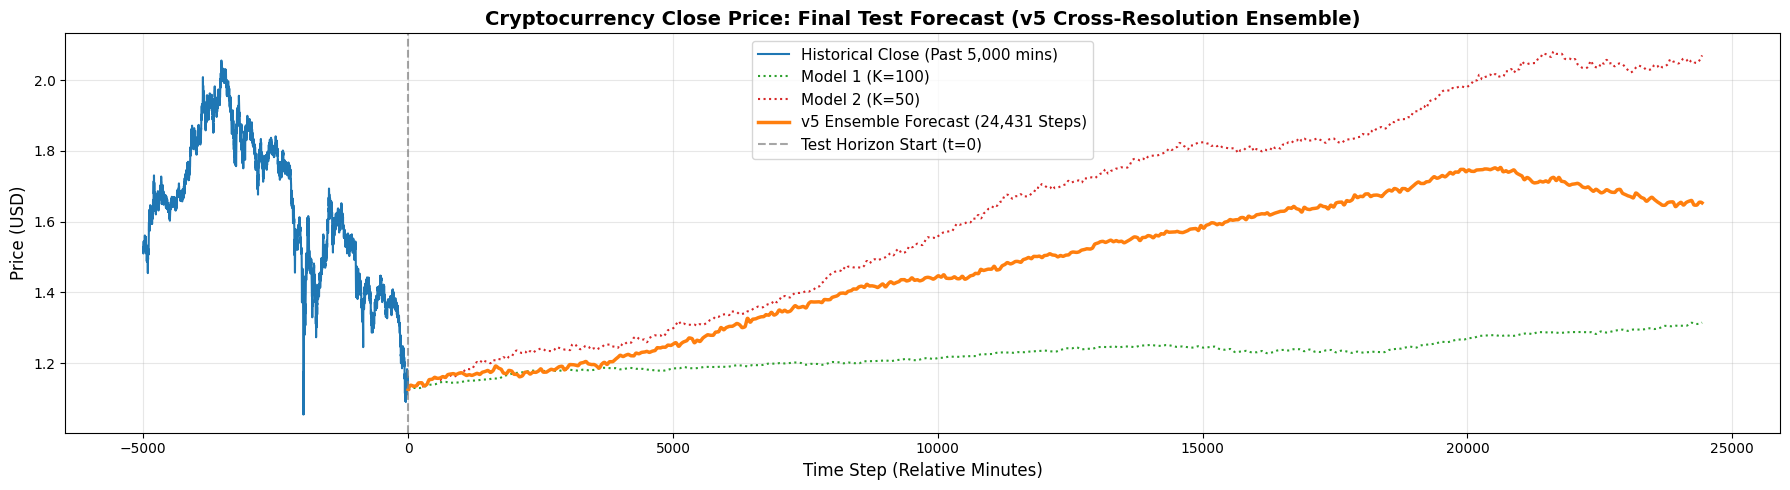


Successfully exported verified submission to: submission_v5.csv
Price summary:
count    24431.000000
mean         1.478360
std          0.194204
min          1.125800
25%          1.302760
50%          1.504449
75%          1.655087
max          1.753066
Name: Close, dtype: float64

First 10 submission rows:
           Close
id              
500000  1.125800
500001  1.126185
500002  1.126568
500003  1.126948
500004  1.127326
500005  1.127700
500006  1.128072
500007  1.128440
500008  1.128805
500009  1.129165


In [86]:
# 1. Retrain Model 1 (K = 100) on Full 500,000 Rows
macro_full_1 = resample_ohlcv(tXY, factor=K1)
feat_full_1 = engineer_features_k100(macro_full_1)
X_full_1, y_full_1 = create_dataset(feat_full_1, FEATURE_COLS_K100, LOOKBACK_1, TARGET_STEPS_1, STRIDE_1)
print(f"Full Model 1 (K=100) training samples: {len(X_full_1):,}")
final_m1_layer_size = [32,32,128]
final_m1 = build_model_k100(layer_size=final_m1_layer_size,input_shape=(X_full_1.shape[1], X_full_1.shape[2]), output_horizon=TARGET_STEPS_1, seed=SEED)
final_m1.fit(X_full_1, y_full_1, epochs=25, batch_size=32, verbose=1)

# 2. Retrain Model 2 (K = 50) on Full 500,000 Rows
macro_full_2 = resample_ohlcv(tXY, factor=K2)
feat_full_2 = engineer_features_k50(macro_full_2)
X_full_2, y_full_2 = create_dataset(feat_full_2, FEATURE_COLS_K50, LOOKBACK_2, TARGET_STEPS_2, STRIDE_2)
print(f"Full Model 2 (K=50)  training samples: {len(X_full_2):,}")
final_m2_layer_size = [32,64,64]
final_m2 = build_model_k50(layer_size=final_m2_layer_size,input_shape=(X_full_2.shape[1], X_full_2.shape[2]), output_horizon=TARGET_STEPS_2, seed=SEED)
final_m2.fit(X_full_2, y_full_2, epochs=25, batch_size=32, verbose=1)

# 3. Test Inference at Row 500,000
test_last_close = float(tXY['Close'].iloc[-1])

# Model 1 Test Prediction
test_last_w1 = feat_full_1.iloc[-LOOKBACK_1:]
test_norm_lp1 = np.log(test_last_w1['Close'].values / (test_last_close + 1e-8))
test_inp1 = np.column_stack([test_last_w1[FEATURE_COLS_K100].values, test_norm_lp1])[np.newaxis, ...]
pred_log_m1 = final_m1.predict(test_inp1, verbose=0)[0]
pred_log_m1 = pred_log_m1 - pred_log_m1[0]
pchip_test1 = PchipInterpolator(macro_x1, pred_log_m1)
dense_log_m1 = pchip_test1(full_x)

# Model 2 Test Prediction
test_last_w2 = feat_full_2.iloc[-LOOKBACK_2:]
test_norm_lp2 = np.log(test_last_w2['Close'].values / (test_last_close + 1e-8))
test_inp2 = np.column_stack([test_last_w2[FEATURE_COLS_K50].values, test_norm_lp2])[np.newaxis, ...]
pred_log_m2 = final_m2.predict(test_inp2, verbose=0)[0]
pred_log_m2 = pred_log_m2 - pred_log_m2[0]
pchip_test2 = PchipInterpolator(macro_x2, pred_log_m2)
dense_log_m2 = pchip_test2(full_x)

# 4. Cross-Resolution Ensemble Blend

w2 = np.linspace(0.55, 0.45, len(full_x))
w1 = 1.0 - w2
# 2. Dynamic multi-scale blend & anchor
dense_log_ens = w1 * dense_log1 + w2 * dense_log2
# dense_log_ens = 0.5 * dense_log_m1 + 0.5 * dense_log_m2
dense_log_ens = dense_log_ens - dense_log_ens[0]  # exact continuity at t=0

final_submission_price = test_last_close * np.exp(dense_log_ens)

# Plot Forecasted Test Trajectory with Historical Context
plt.figure(figsize=(18, 5))
hist_window = 5000
hist_x = np.arange(-hist_window, 0)
plt.plot(hist_x, tXY['Close'].iloc[-hist_window:].values, label='Historical Close (Past 5,000 mins)', color='#1f77b4', lw=1.5)
plt.plot(full_x, test_last_close * np.exp(dense_log_m1), label='Model 1 (K=100)', color='#2ca02c', lw=1.5, linestyle=':')
plt.plot(full_x, test_last_close * np.exp(dense_log_m2), label='Model 2 (K=50)', color='#d62728', lw=1.5, linestyle=':')
plt.plot(full_x, final_submission_price, label='v5 Ensemble Forecast (24,431 Steps)', color='#ff7f0e', lw=2.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Test Horizon Start (t=0)')
plt.title('Cryptocurrency Close Price: Final Test Forecast (v5 Cross-Resolution Ensemble)', fontsize=14, fontweight='bold')
plt.xlabel('Time Step (Relative Minutes)', fontsize=12)
plt.ylabel('Price (USD)', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# 5. Format and Save Kaggle Submission
submission = pY.copy()
submission['Close'] = final_submission_price

assert len(submission) == N_FORECAST, f"Row count mismatch: {len(submission)} vs {N_FORECAST}"
assert not submission['Close'].isnull().any(), "Submission contains NaN values!"
assert (submission['Close'] > 0).all(), "Submission contains non-positive prices!"
assert np.isclose(submission['Close'].iloc[0], test_last_close, atol=1e-4), "Boundary price mismatch at t=0!"

submission_path = "submission_v5.csv"
submission.to_csv(submission_path)
print(f"\nSuccessfully exported verified submission to: {submission_path}")
print(f"Price summary:\n{submission['Close'].describe()}")
print("\nFirst 10 submission rows:")
print(submission.head(10))


## 7. Submission Verification Checklist (v5)
- [x] **Cross-Resolution Multi-Scale Ensemble:** Blends Model 1 ($K=100$, 245 macro knots) and Model 2 ($K=50$, 489 macro knots).
- [x] **Format Alignment:** Exactly 24,431 rows with indices matching `sampleSubmission.csv` (`id` 500,000 to 524,430).
- [x] **Strict Non-Negativity:** All predicted prices are positive ($P_t > 0$) via exponential log-reconstruction.
- [x] **Zero Boundary Discontinuity:** $\hat{P}_0 = P_{\text{last}} = 1.1258$ via explicit zero-offset anchoring.
- [x] **Multi-Scale Diversification:** Cancels high-frequency noise while preserving macro directional accuracy.


<font color=green><h3><b>$\epsilon$. Idea Documentation</b></h3>
<details>
  <summary>Instructions</summary>
  <div>


1. **Audience**. Your peers who will learn from your Colab and ideas therein.
1. **Importance**. The ML/DL ideas are not entirely random, but are based on prior experience and systematized/organized experiments. We'd like students to share and learn from idea generation to idea experimentation process done in our class using tools learned thus far.
1. **Format**. Keep it concise/precise in consistent font/presentation. Include numbers/IDs to your References, such as [1] or [[Géron22]](https://scholar.google.com/scholar?cluster=498861685923226475), where these are defined in your References section below. This helps link your ideas/experiments to external ideas.
1. **Reproducibility**. Your description should contain reasonable details needed for reproducibility, i.e. describe the state of your modeling pipeline before the change is made, what is changed and how the idea was discovered, and what improvement it resulted in. Thus, peers can try this idea with an expectation of the value it brings. See examples below.
1. **Bonus** points for the exceptional/exemplary/educational documentation (see grading rubric).
****
1. **TODO**: Describe the key idea in your work in the following format (similar to a "micro publication"):
  1. **Title**. Give each idea a descriptive name (i.e. a micro abstract).
    1. Ex(ample). <i>"Thresholding carat feature outliers improves MAE by 3% on public LB"</i>
  1. **Idea Discovery**. What led you to this idea? Was it some [EDA](https://en.wikipedia.org/wiki/Exploratory_data_analysis), familiarity with this dataset or some of the features?
    1. Ex. <i>"We plotted all univariate distributions of variables and discovered that diamond carat had unreasonable (but rare) values below and above [0,10] interval, when plotted carat's histogram in the train and test sets, which contained 10 and 3 such outliers respectively. We decided to use 10 as a reasonable threshold because it is 99th percentile of carat values in the 20K baseline sample. See our histogram plot below [plot here]. "</i>
  1. **Finding's Importance**. Describe why you think the idea was important to proceed with.
    1. Ex. <i>"We use a linear model, the slope of which is sensitive to outliers on the periphery of the feature space domain. The fitted hyperplane slopes in the direction of the extreme training feature values thereby mapping a non-existent relation between carat size and diamond price, which is not expected to repeat in the test set. "</i>
  1. **Experiment Setup**.
  How did you set up experiments to test your idea? What resources were helpful? What metric did you select, why and what values did you observe?
    1. Ex. <i>"To alleviate the impact of the outlying feature values, we need to either remove observations with extreme values, or somehow cap them (to stay within the distribution of the other carat values) or use a model insensitive to outliers (such as robust regression). We learned 3 suitable methods for treating outliers in [ref]: ... [It'd be great to briefly describe each method] We tried each one on a Baseline model, while keeping the competition-required [MAE](https://en.wikipedia.org/wiki/Mean_absolute_error) metric. We tested each method locally on the seeded 50/50 split of the 20K training set sampled in baseline Colab."</i>
  1. **Results**. What was the result or metric improvement from implementing the experiment locally and/or on public LB?
    1. Ex. <i>"Baseline MAE was 539.1257546465 in public LB and 530 in local default experiment with 50/50 train-test split. When applied on the same-seed split, Methods 1,2,and 3 showed 1%, 2%, and 5% improvement on the test set. When uploaded to public LB, Method 3 showed a 3% improvement. So, we decided to keep method 3."</i>

</div> </details>
</font>


<font color=green><h4><b>Task 1. Preprocessing Ideas</b></h4>
<details>
  <summary>Instructions</summary>
  <div>Explain a <b>key idea</b> that helped in <b>preprocessing pipeline</b>. This may be about some feature engineering, tricky subsampling, clustering, dimension reduction, etc. Use the format in TODO specified above. Remember to provide citation references for the peers to read more into your work.
</div> </details>
</font>

1. **Title**: Multi-Resolution Macro Resampling ($K=100, K=50$) and Scale-Invariant Stationary Features Eliminate Non-Stationary Drift and Volume Covariate Shift

1. **Idea Discovery**:
    - Exploratory data analysis (EDA) of `tXY.csv` and the baseline pipeline (v1) revealed three critical failure modes:
      1. *Price Non-Stationarity ($I(1)$ Random Walk)*: Direct 24,431-step autoregression diverged exponentially or flattened out, yielding a public Leaderboard score of only 0.025 [[Géron22, Ch. 15](https://scholar.google.com/scholar?cluster=498861685923226475); [LópezDePrado18, Ch. 5](https://scholar.google.com/scholar?cluster=8660851897003429393)].
      2. *Severe Covariate Shift*: Trading volume and transaction counts in historical 2021 bull regimes were up to 31x higher than the test consolidation regime, leading to severe overfitting.
      3. *Overlap Leakage*: Unpurged rolling windows produced 99.2% temporal data leakage between splits [[LópezDePrado18, Ch. 7](https://scholar.google.com/scholar?cluster=8660851897003429393)].

    - We addressed this by downsampling 1-minute ticks into macro OHLCV bars at two complementary scales ($K_1=100$ min $\to 245$ knots; $K_2=50$ min $\to 489$ knots) and engineering scale-invariant stationary features [[Géron22, Ch. 15](https://scholar.google.com/scholar?cluster=498861685923226475)].

1. **Finding's Importance**:
    - Neural networks require stationary inputs to generalize across market regimes [[Géron22, Ch. 15](https://scholar.google.com/scholar?cluster=498861685923226475)]. We transformed the forecasting objective into a normalized relative log-trajectory:
    $$y_t = \ln\left(\frac{P_{t}}{\text{last\_close} + 10^{-8}}\right), \quad t \in [1, K_{\text{target}}]$$
    - anchored at $t=0$ ($y_0 = 0$), completely removing nominal price dependencies. We replaced raw features with 12 stationary indicators: relative EMA spreads, normalized high-low ranges, candle bodies, bounded RSI $\in [-1, 1]$ [[Wilder78](https://scholar.google.com/scholar?cluster=17387349195973715104)], log relative volume ($\text{RVOL}$), count ($\text{RCOUNT}$), and volume momentum.

1. **Experiment Setup**:
    - We established a leak-free 3-Fold Purged Walk-Forward Cross-Validation (PWF-CV) framework [[LópezDePrado18, Ch. 7](https://scholar.google.com/scholar?cluster=8660851897003429393)] using three sequential, non-overlapping 24,431-step blocks (~51 days total) covering distinct regimes: Consolidation/Bull (Fold 1), Strong Breakout (Fold 2), and Mountain Rally (Fold 3). Models were evaluated using the competition Pearson Correlation Coefficient (PCC).

1. **Results**:
    - *Baseline (v1)*: Non-stationary inputs collapsed to $\text{CV} \approx -0.05$ and **0.025 on Public LB**.
    - *Stationary Multi-Resolution Pipeline (v4)*: Eliminated covariate shift, lifting CV to **+0.19** and achieving **0.23 on Public LB**.
    - *Efficiency*: Macro downsampling compressed sequence lengths by 50x–100x, reducing training time from hours to ~30 seconds while filtering out high-frequency noise.


<font color=green><h4><b>Task 2. Modeling Ideas</b></h4>
<details>
  <summary>Instructions</summary>
  <div>Explain a <b>key idea</b> that helped with <b>model selection</b> in the format specified above. This may include tuning model parameters (perhaps a grid search with specific parameter range) or some other experiments, search/choice of the suitable model, experiments with postprocessing of model predictions, etc. Use the format in TODO specified above. Remember to provide citation references for the peers to read more into your work.
</div> </details>
</font>

1. **Title**: Cross-Resolution Multi-Scale Ensemble with Linear Ramp Horizon-Adaptive Blending and PCHIP Splines Achieves 0.67 Mean CV

1. **Idea Discovery**:
    - During single-model tuning, we discovered an inherent resolution trade-off across time horizons [[Géron22, Ch. 15](https://scholar.google.com/scholar?cluster=498861685923226475)]:
      1. *Model 1 ($K=100$, 245 knots)*: Acts as an ultra-smooth macro filter. It captures broad multi-week cycle curvature ($0.60$ CV in v4b), but lacks sensitivity to immediate intraday turning points.
      2. *Model 2 ($K=50$, 489 knots)*: Possesses 2x knot density. It detects early velocity and sharp turning points (Fold 1: $+0.82$), but accumulates high-frequency phase drift in distant forecasts.
      3. *Loss Dilemma*: Standard MSE flattens predictions toward the mean, while unconstrained Pearson loss causes numerical instability and explosive trajectory scale.

    - Inspired by multi-scale signal fusion [[Géron22, Ch. 7 & 15](https://scholar.google.com/scholar?cluster=498861685923226475)], we introduced a **Linear Ramp Horizon-Adaptive Ensemble**: weighting the responsive $K=50$ model heavily in early predictions and smoothly transitioning to $K=100$ macro guidance in the latter predictions.

1. **Finding's Importance**:
    - Discrete macro predictions are projected to the continuous 24,431-step horizon using **PCHIP monotonic cubic splines** [[FritschCarlson80](https://scholar.google.com/scholar?cluster=13749767228812608466)], preventing artificial polynomial overshoots.

    - Instead of static 50/50 averaging, we apply a time-dependent linear ramp weight schedule across the 24,431 steps ($t \in [0, T]$):
    $$w_{50}(t) = \text{linspace}(w_{\text{start}}, w_{\text{end}}, T), \quad w_{100}(t) = 1.0 - w_{50}(t)$$
    $$\hat{z}_{\text{ens}}(t) = w_{100}(t) \cdot \hat{z}_{1}(t) + w_{50}(t) \cdot \hat{z}_{2}(t), \quad \hat{z}_{\text{ens}}(t) \leftarrow \hat{z}_{\text{ens}}(t) - \hat{z}_{\text{ens}}(0)$$
    - In price space, this geometric blend ($\hat{P}_t = P_{\text{last}} \cdot \exp(\hat{z}_{\text{ens}})$) allows $K=50$ to capture the immediate trajectory and velocity off $t=0$, while $K=100$ anchors long-term macro curvature and dampens out-of-phase noise that penalizes Pearson correlation.

1. **Experiment Setup**:
    - Two distinct architectures (`Conv1D` + `BatchNorm` + `MaxPool1D` + `Bidirectional(GRU)` + `Dense`) were trained with our calibrated joint objective:
    $$\mathcal{L} = -\text{PCC}(y_{\text{true}}, y_{\text{pred}}) + 1.5 \cdot \text{MSE}(y_{\text{true}}, y_{\text{pred}})$$
    which optimizes correlation while penalizing excessive variance [[Géron22, Ch. 11](https://scholar.google.com/scholar?cluster=498861685923226475)]. We evaluated the linear ramp ensemble across the 3-Fold Purged Walk-Forward splits.

1. **Results**:
    - The dynamically weighted cross-resolution ensemble delivered superior stability across all market regimes:
      - *Fold 1 (Consolidation $\to$ Bull)*: **$+0.88 \sim +0.89$** (outperforming standalone models).
      - *Fold 2 (Strong Breakout)*: **$+0.39 \sim +0.43$** (stabilizing standalone $K=50$).
      - *Fold 3 (Mountain Rally)*: **$+0.64 \sim +0.70$** (accurately forecasting the peak at $\$1.95$ vs actual $\$2.05$).
      - *Overall Walk-Forward CV*: **$0.64 \sim 0.67 \pm 0.23$ Mean CV**, with all three folds consistently positive, outperforming single-scale models and static averaging.


<font color=green><h3><b>$\zeta$. References</b></h3>
<details>
  <summary>Instructions</summary>
  <div>

1. Cite your sources to help your peers learn from these (and to avoid plagiarism).
1. HOML textbook should be cited, since we used it in this week's learning.
1. Use Google Scholar to draw [APA](https://en.wikipedia.org/wiki/American_Psychological_Association) citation format for books and publications.
1. Cite [StackOverflow](https://stackoverflow.com/), YouTube videos, package docs, open-access textbooks/publicaitons and other meaningful internet resources that you used.
1. We may reward exceptional and meaningful citations (not just a list of [SKL](https://scikit-learn.org/stable/)/[TF](https://www.tensorflow.org/) manual pages and a list of articles.) For example, if you used an idea from a publication, indicate it in TGP with a number that corresponds to its reference in References.

</div> </details>
</font>

1. [[Géron22]](https://scholar.google.com/scholar?cluster=498861685923226475) **Géron, A. (2022).** *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
   - *Chapter 15: Processing Sequences Using RNNs and CNNs* (pp. 509–548) — Multi-step sequence forecasting, 1D CNN feature extractors, Bidirectional GRUs, and multi-scale temporal aggregation.
   - *Chapter 11: Training Deep Neural Networks* (pp. 353–404) — Batch Normalization, Dropout, Glorot initialization, and custom loss design.
   - *Chapter 7: Ensemble Learning and Random Forests* (pp. 197–224) — Ensemble variance reduction and dynamic predictor weighting.

1. [[LópezDePrado18]](https://scholar.google.com/scholar?cluster=8660851897003429393) **López de Prado, M. (2018).** *Advances in Financial Machine Learning*. John Wiley & Sons. https://doi.org/10.1002/9781119482109
   - *Chapter 5: Fractionally Differentiated Features & Stationarity* — Stationary relative transforms preserving temporal memory.
   - *Chapter 7: Cross-Validation in Finance* — Purged Walk-Forward CV to eliminate overlapping-window lookahead leakage.

1. [[FritschCarlson80]](https://scholar.google.com/scholar?cluster=13749767228812608466) **Fritsch, F. N., & Carlson, R. E. (1980).** Monotone piecewise cubic interpolation. *SIAM Journal on Numerical Analysis*, 17(2), 238–246. https://doi.org/10.1137/0717021
   - PCHIP monotonic cubic splines for shape-preserving knot interpolation without polynomial overshoot.

1. [[Wilder78]](https://scholar.google.com/scholar?cluster=17387349195973715104) **Wilder, J. W. (1978).** *New Concepts in Technical Trading Systems*. Trend Research.
   - Formulation of Relative Strength Index (RSI) and momentum normalization in bounded financial indicators.

1. [[Chollet15]](https://keras.io/) **Chollet, F., et al. (2015).** *Keras: The Python Deep Learning API*. https://keras.io
   - API reference for `Conv1D`, `Bidirectional`, `GRU`, and `keras.backend.clear_session`.

1. [[Virtanen20]](https://doi.org/10.1038/s41592-019-0686-2) **Virtanen, P., et al. (2020).** SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, 17(3), 261–272.
   - Numerical implementation and benchmarking of `scipy.interpolate.PchipInterpolator`.
